In [83]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, silhouette_samples
%matplotlib inline 

Validação

In [17]:
def sil_elbow_scores(range_tuple, init_k , X):
    k_values = range_tuple
    first=True
    for k in k_values:
        #print(type(init_k).__name__)
       # if type(init_k).__name__ != 'str':
        #    init_k = np.array(centroides.iloc[0:k,:].reset_index(drop=True))
        #print(init_k)
        kmeans = KMeans(n_clusters=k, init = init_k, n_init=1) #init default = 'k-means++'
        cluster_labels = kmeans.fit_predict(X)
        score_wss = round(kmeans.inertia_ ,1)
        silhueta = round(silhouette_score(X, cluster_labels),4)
        #plt.plot(Nc,score)
        #plt.xlabel('Number of Clusters')
        #plt.ylabel('Within Cluster Sum of Squares')
        #plt.title('Elbow Curve')
        #plt.show()
        resultados_aux = {
            'score_wss': score_wss,
            'silhueta': silhueta
        }
        resultados_aux = pd.DataFrame(resultados_aux, index = [k])
        if first == True:
            resultados_final = resultados_aux
            first = False
        else:
            resultados_final = pd.concat([resultados_final, resultados_aux],axis =0)


    plt.plot(resultados_final.index,resultados_final.score_wss)
    plt.xlabel('Number of Clusters')
    plt.ylabel('Within Cluster Sum of Squares')
    plt.title('Elbow Curve')
    plt.show()

    plt.plot(resultados_final.index,resultados_final.silhueta)
    plt.xlabel('Number of Clusters')
    plt.ylabel('Silhouette')
    plt.title('')
    plt.show()

    print(resultados_final)

Sem defininção de Método

In [9]:
df_dados = pd.read_csv('Bases/agrupamento.csv')
df_centroides = pd.read_csv('Bases/centroides_iniciais.csv')

In [11]:
df_centroides.iloc[1]

V1    0.911179
V2   -0.010054
V3   -0.093556
Name: 1, dtype: float64

C:\Users\diego\Anaconda3\lib\site-packages\sklearn\cluster\k_means_.py:896: RuntimeWarning: Explicit initial center position passed: performing only one init in k-means instead of n_init=10
  return_n_iter=True)


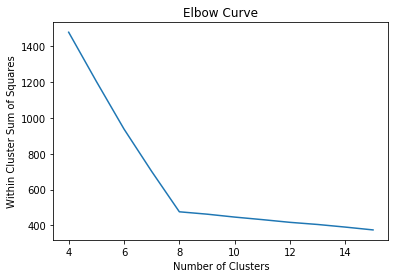

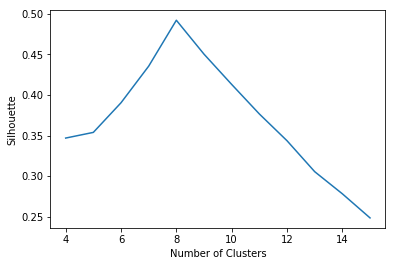

In [82]:
first = True
for k in range(4,16):
    X=df_dados
    kmeans = KMeans(n_clusters=k,init=df_centroides.iloc[np.arange(k)]) #, init = pd.DataFrame(df_centroides.iloc[k])) #init default = 'k-means++'
    cluster_labels = kmeans.fit_predict(X)
    score_wss = round(kmeans.inertia_ ,1)
    silhueta = round(silhouette_score(X, cluster_labels),4)
    resultados_aux = {
        'score_wss': score_wss,
        'silhueta': silhueta
    }
    resultados_aux = pd.DataFrame(resultados_aux, index = [k])
    if first == True:
        resultados_final = resultados_aux
        first = False
    else:
        resultados_final = pd.concat([resultados_final, resultados_aux],axis =0)


plt.plot(resultados_final.index,resultados_final.score_wss)
plt.xlabel('Number of Clusters')
plt.ylabel('Within Cluster Sum of Squares')
plt.title('Elbow Curve')
plt.show()

plt.plot(resultados_final.index,resultados_final.silhueta)
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette')
plt.title('')
plt.show()

Para o melhor K pelo metodo do cotovelo

In [80]:
df_centroides
kmeans = KMeans(n_clusters=8,init=df_centroides.iloc[np.arange(8)]) #, init = pd.DataFrame(df_centroides.iloc[k])) #init default = 'k-means++'
cluster_labels = kmeans.fit_predict(X)

C:\Users\diego\Anaconda3\lib\site-packages\sklearn\cluster\k_means_.py:896: RuntimeWarning: Explicit initial center position passed: performing only one init in k-means instead of n_init=10
  return_n_iter=True)


In [81]:
kmeans.inertia_

476.1691752377431